# Tarea calificada 1 INAR_2023


## Cat vs. Dog Image Classification

Este ejercicio consiste en desarrollar un modelo deep learning CNN (aunque eres libre de probar otras alternativas) para una dataset que contiene imágenes de perros y gatos (exclusivamente). 

Se debe entregar este notebook (como mínimo, se pueden entregar varios notebooks en un .zip) con los siguientes puntos:

1. Carga y pre-proceso de ficheros de datos. (**YA DESARROLLADO, SOLO DEBE SER EJECUTADO**)
2. Configura un (uno al menos, puedes presentar más) modelo CNN para la clasificación perro versus gato.
3. Realiza el entrenamiento y prueba el rendimiento del modelo con el conjunto de test que hemos recopilado en clase este año.

El dataset y la primera parte de este notebook están obtenidos, con infinitas gracias, de

https://colab.research.google.com/github/google/eng-edu/blob/master/ml/pc/exercises/image_classification_part1.ipynb

Por tanto se debe mencionar la siguiente licencia:

#### Copyright 2018 Google LLC.
Licensed under the Apache License, Version 2.0 (the "License"); you may not use this file except in compliance with the License.

You may obtain a copy of the License at

 https://www.apache.org/licenses/LICENSE-2.0

Unless required by applicable law or agreed to in writing, software distributed under the License is distributed on an "AS IS" BASIS, WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
See the License for the specific language governing permissions and limitations under the License.


## 1. Carga y Pre-Proceso de Datos

Descarga por favor el .zip 

cats_and_dogs_filtered.zip

del Blackboard de la tarea en la misma ruta (carpeta) de este notebook y ejecuta los siguientes pasos.

(o si usas Google Colab lo tienes en la dirección anterior)

Mantengo la nota original del origen del dataset.


**NOTE:** The 2,000 images used in this exercise are excerpted from the ["Dogs vs. Cats" dataset](https://www.kaggle.com/c/dogs-vs-cats/data) available on Kaggle, which contains 25,000 images. Here, we use a subset of the full dataset to decrease training time for educational purposes.

In [1]:
#Realiza los imports:
import os
import zipfile

# Descomprimir el archivo zip
local_zip = './dataset_tarea_1_2023.zip'           #Define la ruta del archivo que se va a descomprimir
zip_ref = zipfile.ZipFile(local_zip, 'r')          #Abre el archivo en modo lectura
zip_ref.extractall('')
zip_ref.close()                                    #Cierra el archivo tras completar la extracción

The contents of the .zip are extracted to the base directory `cats_and_dogs_filtered`, which contains `train` and `validation` subdirectories for the training and validation datasets (see the [Machine Learning Crash Course](https://developers.google.com/machine-learning/crash-course/validation/check-your-intuition) for a refresher on training, validation, and test sets), which in turn each contain `cats` and `dogs` subdirectories. 

NOTA: Además, en el mismo directorio donde se descomprime el cats_and_dogs_filtered descomprime el test.zip en un directorio test. 

Si todo está bien nombrado y "colgando" de la misma ruta, te saldrán los siguientes tamaños de conjuntos train     /validation / test (un poco más adelante)

- total training cat images: 1000
- total training dog images: 1000
- total validation cat images: 500
- total validation dog images: 500
- total test cat images: 155
- total test dog images: 158



In [2]:
#Este código crea una estructura de directorios para organizar imágenes de gatos y perros en conjuntos de entrenamiento, validación y prueba. 

base_dir = './dataset_tarea_1_2023'
train_dir = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'validation')
test_dir = os.path.join(base_dir, 'test')

# Directory with our training cat pictures
train_cats_dir = os.path.join(train_dir, 'cats')

# Directory with our training dog pictures
train_dogs_dir = os.path.join(train_dir, 'dogs')

# Directory with our validation cat pictures
validation_cats_dir = os.path.join(validation_dir, 'cats')

# Directory with our validation dog pictures
validation_dogs_dir = os.path.join(validation_dir, 'dogs')

# Directory with our test cat pictures
test_cats_dir = os.path.join(test_dir, 'cats')

# Directory with our test dog pictures
test_dogs_dir = os.path.join(test_dir, 'dogs')

Now, let's see what the filenames look like in the `cats` and `dogs` `train` directories (file naming conventions are the same in the `validation` directory):

In [3]:
# Listar los primeros 10 nombres de archivo de perros en el conjunto de entrenamiento
train_cat_fnames = os.listdir(train_cats_dir)
print(train_cat_fnames[:10])

train_dog_fnames = os.listdir(train_dogs_dir)
train_dog_fnames.sort()
print(train_dog_fnames[:10])

['cat.0.jpg', 'cat.1.jpg', 'cat.10.jpg', 'cat.100.jpg', 'cat.101.jpg', 'cat.102.jpg', 'cat.103.jpg', 'cat.104.jpg', 'cat.105.jpg', 'cat.106.jpg']
['dog.0.jpg', 'dog.1.jpg', 'dog.10.jpg', 'dog.100.jpg', 'dog.101.jpg', 'dog.102.jpg', 'dog.103.jpg', 'dog.104.jpg', 'dog.105.jpg', 'dog.106.jpg']


Let's find out the total number of cat and dog images in the `train` and `validation` directories:

In [4]:
# Mostrar el número total de imágenes en cada categoría para conjuntos de entrenamiento, validación y prueba
print('total training cat images:', len(os.listdir(train_cats_dir)))
print('total training dog images:', len(os.listdir(train_dogs_dir)))
print('total validation cat images:', len(os.listdir(validation_cats_dir)))
print('total validation dog images:', len(os.listdir(validation_dogs_dir)))
print('total test cat images:', len(os.listdir(test_cats_dir)))
print('total test dog images:', len(os.listdir(test_dogs_dir)))

total training cat images: 1000
total training dog images: 1000
total validation cat images: 500
total validation dog images: 500
total test cat images: 461
total test dog images: 277


For both cats and dogs, we have 1,000 training images and 500 test images.

Now let's take a look at a few pictures to get a better sense of what the cat and dog datasets look like. First, configure the matplot parameters:

In [5]:
# Mostrar una muestra de imágenes del conjunto de entrenamiento
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Parameters for our graph; we'll output images in a 4x4 configuration
nrows = 4
ncols = 4

# Index for iterating over images
pic_index = 0

Now, display a batch of 8 cat and 8 dog pictures. You can rerun the cell to see a fresh batch each time:

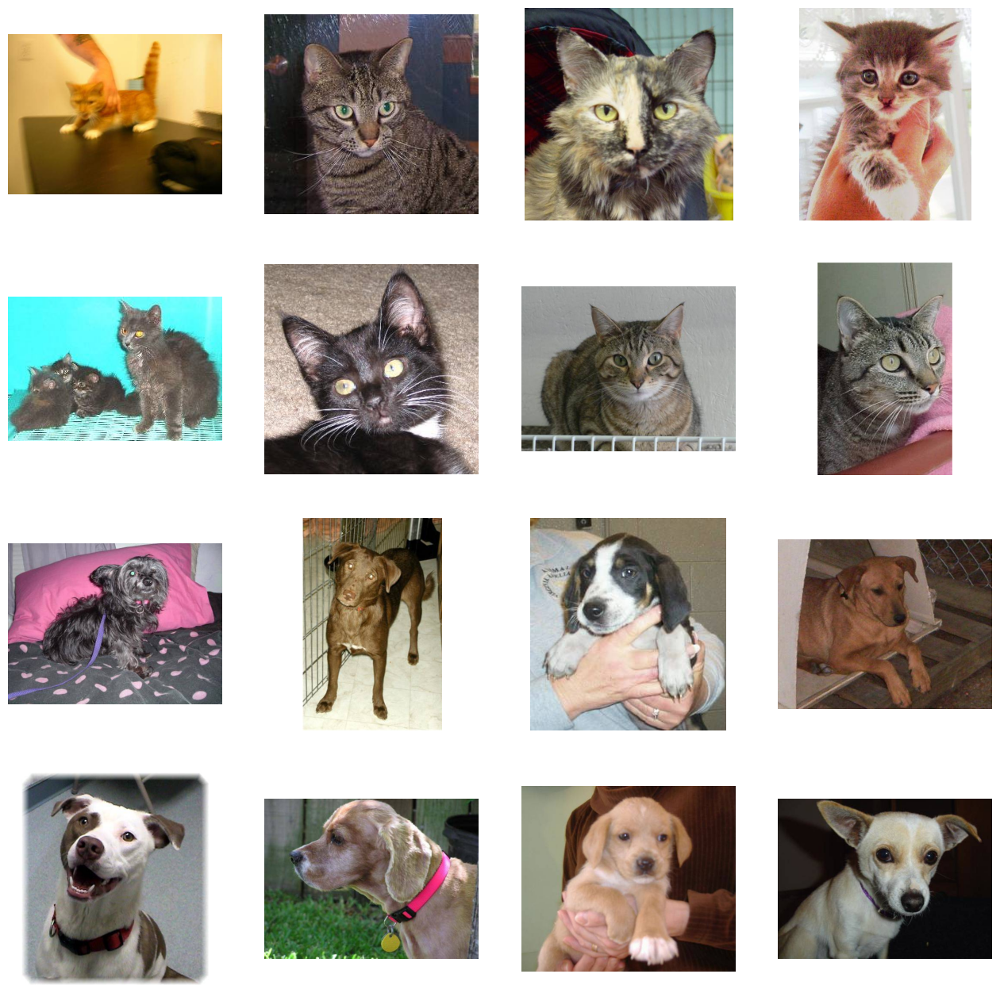

In [6]:
# Configurar la figura de matplotlib y ajustar su tamaño para que quepan 4x4 imágenes
fig = plt.gcf()
fig.set_size_inches(ncols * 4, nrows * 4)

# Mostrar 8 imágenes de gatos y 8 imágenes de perros
pic_index += 8
next_cat_pix = [os.path.join(train_cats_dir, fname) 
                for fname in train_cat_fnames[pic_index-8:pic_index]]
next_dog_pix = [os.path.join(train_dogs_dir, fname) 
                for fname in train_dog_fnames[pic_index-8:pic_index]]

for i, img_path in enumerate(next_cat_pix+next_dog_pix):
    # Configurar el subplot; los índices de subplot comienzan en 1
    sp = plt.subplot(nrows, ncols, i + 1)
    sp.axis('Off')    # No mostrar ejes (o líneas de cuadrícula)
    img = mpimg.imread(img_path)
    plt.imshow(img)

plt.show()


### Data Preprocessing

Let's set up data generators that will read pictures in our source folders, convert them to `float32` tensors, and feed them (with their labels) to our network. We'll have one generator for the training images and one for the validation images. Our generators will yield batches of 20 images of size 150x150 and their labels (binary).

As you may already know, data that goes into neural networks should usually be normalized in some way to make it more amenable to processing by the network. (It is uncommon to feed raw pixels into a convnet.) In our case, we will preprocess our images by normalizing the pixel values to be in the `[0, 1]` range (originally all values are in the `[0, 255]` range).

In Keras this can be done via the `keras.preprocessing.image.ImageDataGenerator` class using the `rescale` parameter. This `ImageDataGenerator` class allows you to instantiate generators of augmented image batches (and their labels) via `.flow(data, labels)` or `.flow_from_directory(directory)`. These generators can then be used with the Keras model methods that accept data generators as inputs: `fit_generator`, `evaluate_generator`, and `predict_generator`.

In [7]:
#Realiza los imports necesarios:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical

# Crear generadores de imágenese que se configuran para escalar los valores de píxeles de las imágenes de todos los conjuntos
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# Definir generadores de datos para conjuntos de entrenamiento, validación y prueba
base_dir = './dataset_tarea_1_2023'
train_dir = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'validation')
test_dir = os.path.join(base_dir, 'test')


# Flow training images in batches of 20 using train_datagen generator
train_generator = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels='inferred',
    label_mode='categorical',
    class_names=None,
    color_mode='rgb',
    batch_size=32,
    image_size=(256, 256),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation='bilinear',
    follow_links=False,
    crop_to_aspect_ratio=False)


# Flow training images in batches of 20 using train_datagen generator
validation_generator = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    labels='inferred',
    label_mode='categorical',
    class_names=None,
    color_mode='rgb',
    batch_size=32,
    image_size=(256, 256),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation='bilinear',
    follow_links=False,
    crop_to_aspect_ratio=False)

# Flow training images in batches of 20 using train_datagen generator
test_generator = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels='inferred',
    label_mode='categorical',
    class_names=None,
    color_mode='rgb',
    batch_size=32,
    image_size=(256, 256),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation='bilinear',
    follow_links=False,
    crop_to_aspect_ratio=False)



Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Found 738 files belonging to 2 classes.


# 2. Neural Transfer

In [8]:
#Realizar los imports necesarios:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout

# Cargar el modelo VGG16 preentrenado
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(256, 256, 3))

# Congelar todas las capas convolucionales del modelo
for layer in base_model.layers:
    layer.trainable = False

#Se crea un modelo secuencial que representa una secuencia lineal de capas.
model = Sequential()

# Añadir el modelo base VGG16
model.add(base_model)

# Añadir capas adicionales para adaptar el modelo a tus clases:
        #La capa Flatten convierte la salida de las capas anteriores en un vector unidimensional para preparar los datos para las capas
        #Las capas densas combinan todas las características aprendidas hasta ese punto y realizan operaciones para realizar la clasificación final.
        #Las capas Dropout previenen el sobreajuste ya que apagan aleatoriamente algunas neuronas, esto mejora la generalización del modelo

model.add(Flatten())
model.add(Dense(1024, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(2, activation='softmax'))  # 2 clases: gato y perro

# Compilar el modelo
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Mostrar el resumen del modelo
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg16 (Functional)          (None, 8, 8, 512)         14714688  
                                                                 
 flatten (Flatten)           (None, 32768)             0         
                                                                 
 dense (Dense)               (None, 1024)              33555456  
                                                                 
 dropout (Dropout)           (None, 1024)              0         
                                                                 
 dense_1 (Dense)             (None, 2)                 2050      
                                                                 
Total params: 48272194 (184.14 MB)
Trainable params: 33557506 (128.01 MB)
Non-trainable params: 14714688 (56.13 MB)
_________________________________________________________________


# 3. Entrenamiento del modelo (.fit) y rendimiento del modelo (accuracy) con conjunto test

Epoch 1/15
63/63 [==============================] - 360s 6s/step - loss: 14.3990 - accuracy: 0.9165 - val_loss: 5.9558 - val_accuracy: 0.9540
Epoch 2/15
63/63 [==============================] - 361s 6s/step - loss: 3.2595 - accuracy: 0.9685 - val_loss: 2.8587 - val_accuracy: 0.9760
Epoch 3/15
63/63 [==============================] - 360s 6s/step - loss: 2.1850 - accuracy: 0.9810 - val_loss: 3.3866 - val_accuracy: 0.9730
Epoch 4/15
63/63 [==============================] - 360s 6s/step - loss: 0.8265 - accuracy: 0.9865 - val_loss: 3.3510 - val_accuracy: 0.9750
Epoch 5/15
63/63 [==============================] - 361s 6s/step - loss: 0.6204 - accuracy: 0.9905 - val_loss: 5.0122 - val_accuracy: 0.9740
Epoch 6/15
63/63 [==============================] - 363s 6s/step - loss: 0.1692 - accuracy: 0.9955 - val_loss: 4.8315 - val_accuracy: 0.9700
Epoch 7/15
63/63 [==============================] - 367s 6s/step - loss: 0.8035 - accuracy: 0.9930 - val_loss: 4.4827 - val_accuracy: 0.9740
Epoch 8/15
6

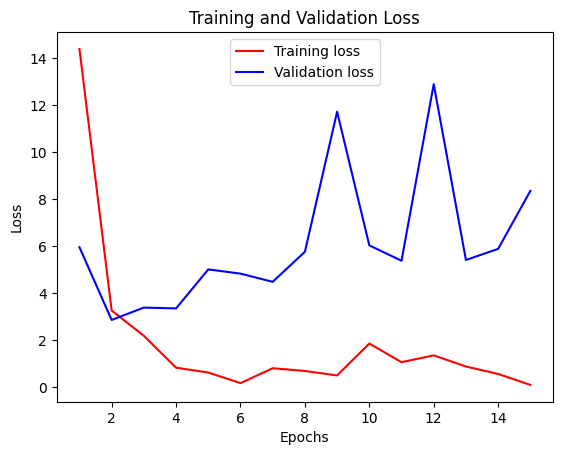

In [9]:
# Entrenar el modelo con el callback
history = model.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=15,  # ajusta según sea necesario
    validation_data=validation_generator,
    validation_steps=len(validation_generator)
)

# Mostrar el progreso de la training loss y la validation loss
train_loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(train_loss) + 1)

# Graficar la training loss en rojo y la validation loss en azul
plt.plot(epochs, train_loss, 'r', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [10]:
test_loss, test_acc = model.evaluate(test_generator)
print('test_acc:', test_acc)

24/24 [==============================] - 90s 4s/step - loss: 67.9431 - accuracy: 0.8266
test_acc: 0.8265582919120789


1/1 [==============================] - 4s 4s/step


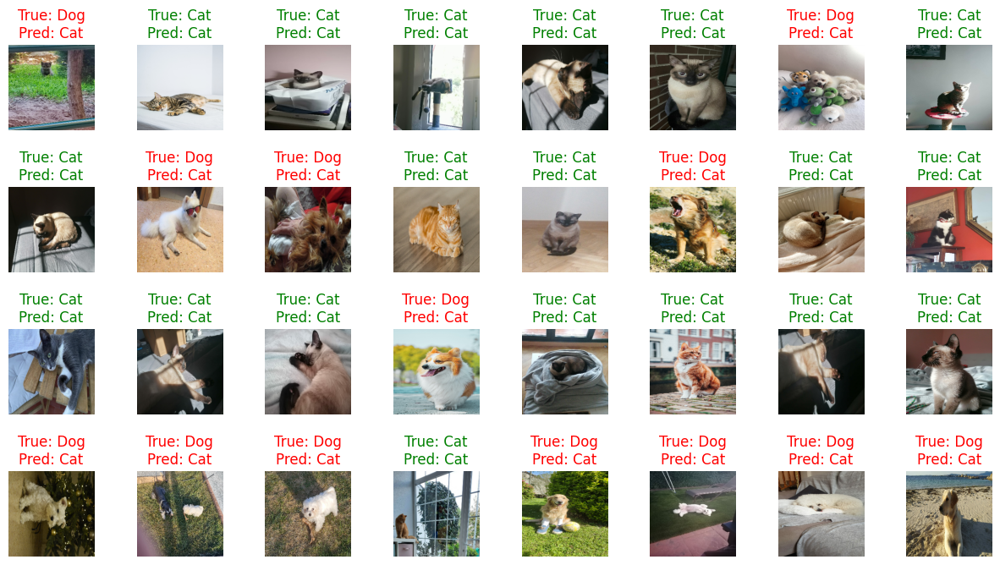

In [11]:
# Visualizar algunas imágenes de prueba junto con las predicciones

# Obtener algunas imágenes y etiquetas de prueba
sample_images, sample_labels = next(iter(test_generator))

# Normalizar los valores de píxeles en el rango [0, 1]
sample_images_normalized = sample_images / 255.0

# Obtener predicciones del modelo
predictions = model.predict(sample_images_normalized)

# Configurar el diseño de las imágenes con más espaciado
nrows = 4
ncols = 8
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 8))
plt.subplots_adjust(hspace=0.5, wspace=0.5)  # Ajustar el espaciado entre subparcelas

for i in range(nrows * ncols):
    ax = axes[i // ncols, i % ncols]
    
    # Mostrar imágenes normalizadas
    ax.imshow(sample_images_normalized[i])
    
    ax.axis('off')
    true_label = 'Cat' if sample_labels[i][0] == 1 else 'Dog'
    pred_label = 'Cat' if predictions[i][0] > 0.765 else 'Dog'
    ax.set_title(f'True: {true_label}\nPred: {pred_label}', color='green' if true_label == pred_label else 'red')

plt.show()

# 4. Trabajo adicional (Neural Transfer, Fine Tuning, visualización de capas intermedias ...)

Imports y carga de imagenes

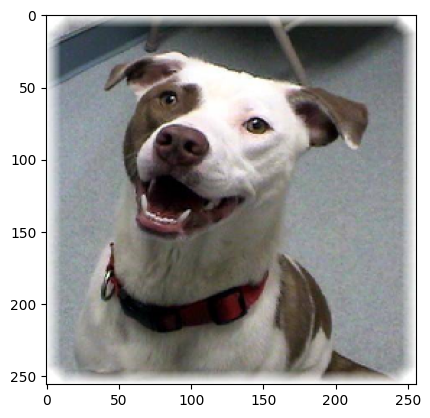

In [12]:
#Realiza los imports necesarios:
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.applications.vgg16 import preprocess_input

# Cargar la imagen
img_path = './Fotos/dog.101.jpg'
img = image.load_img(img_path, target_size=(256, 256))

# Convertir la imagen a un array numpy y expandir las dimensiones para que coincida con el tamaño de entrada del modelo
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Normalizar la imagen
img_array = preprocess_input(img_array)

# Visualizar la imagen
plt.imshow(img)
plt.show()


 Obtención de capas intermedias del modelo VGG16

In [13]:
# Obtener las capas intermedias del modelo VGG16
layer_names = ['block1_conv1', 'block2_conv1', 'block3_conv1', 'block4_conv1', 'block5_conv1']

# Asegúrate de que 'base_model' contiene las capas convolucionales de VGG16
outputs = [base_model.get_layer(name).output for name in layer_names]

# Crear un modelo que devuelva las activaciones de las capas intermedias
activation_model = Model(inputs=base_model.input, outputs=outputs)


Obtención de activaciones de las capas intermedias

In [14]:
# Obtener las activaciones de las capas intermedias
activations = activation_model.predict(img_array)

1/1 [==============================] - 0s 187ms/step


Visualización de las activaciones de las capas intermedias

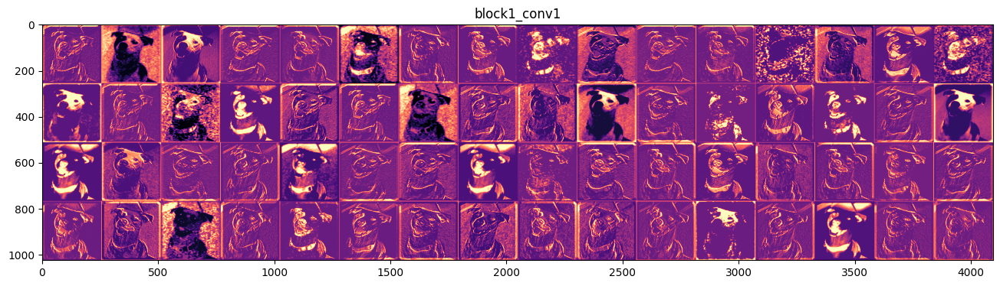

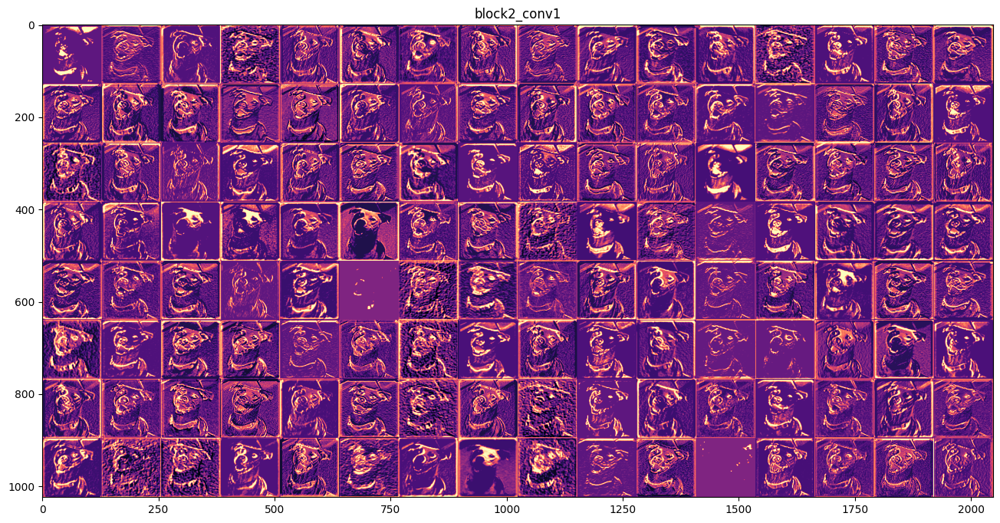

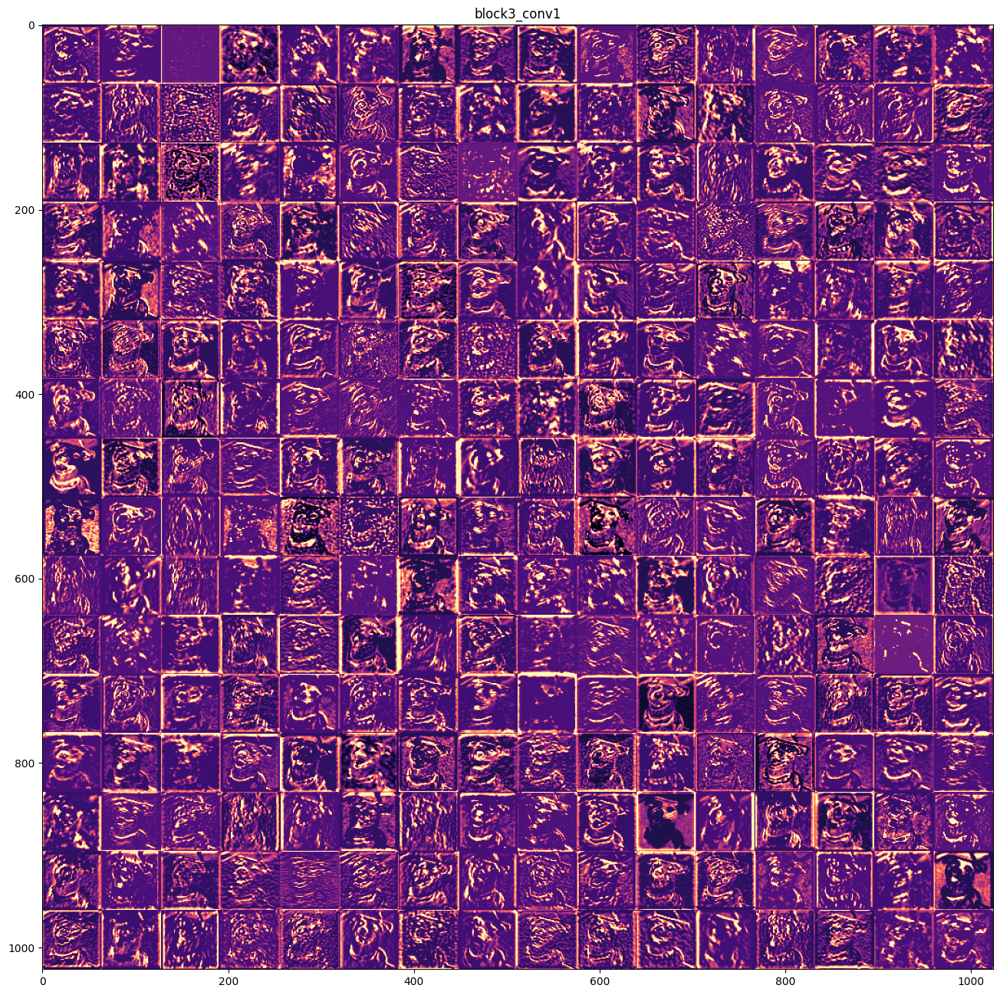

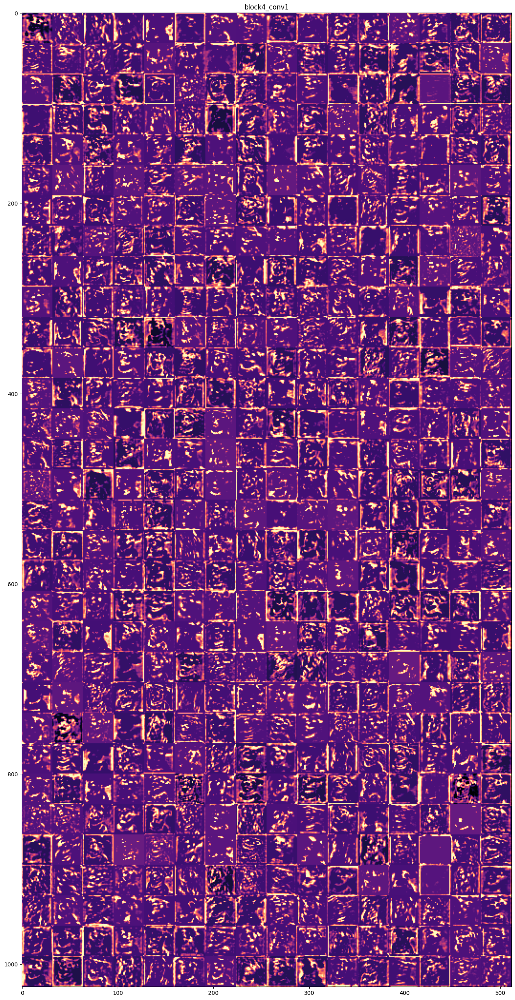

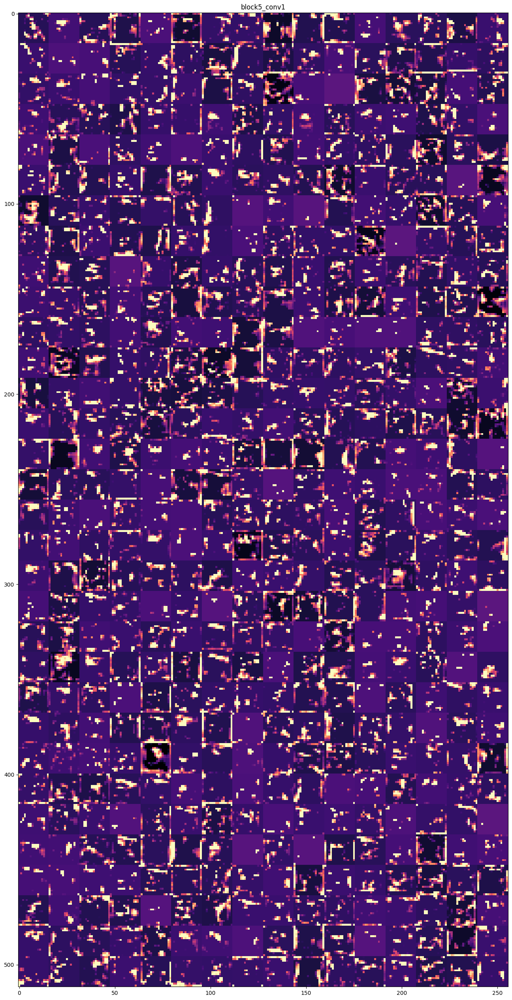

In [15]:
# Visualizar las activaciones de las capas intermedias
images_per_row = 16
for layer_name, layer_activation in zip(layer_names, activations):
    n_features = layer_activation.shape[-1]  # Número de características en la activación del mapa
    size = layer_activation.shape[1]  # Tamaño de la activación del mapa
    
    n_cols = n_features // images_per_row
    display_grid = np.zeros((size * n_cols, images_per_row * size))

    #Visualización de activaciones de capas convolucionales al ajustar y combinar las imágenes de activación de cada filtro
    #Normalizar y variar los valores para mejorar la visualización.
    for col in range(n_cols):
        for row in range(images_per_row):
            channel_image = layer_activation[0, :, :, col * images_per_row + row]
            channel_image -= channel_image.mean()
            channel_image /= channel_image.std()
            channel_image *= 64
            channel_image += 128
            channel_image = np.clip(channel_image, 0, 255).astype('uint8')
            display_grid[col * size : (col + 1) * size, row * size : (row + 1) * size] = channel_image
    
    scale = 1. / size
    plt.figure(figsize=(scale * display_grid.shape[1], scale * display_grid.shape[0]))
    plt.title(layer_name)
    plt.grid(False)
    
    #Tras buscar muchos colores decidi elegir 'magma' 
    #ya que debido a la diferencia del color marron de las manchas del perro y el color blanco del resto del pelaje
    #dicho color es el que mejor muestra las imágenes
    plt.imshow(display_grid, aspect='auto', cmap='magma')     

plt.show()
